In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, AutoMinorLocator
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.nonparametric.smoothers_lowess import lowess

data_path = Path('../data')

## Pretraining metrics plots

In [6]:
# computed from scripts/measure_flops.py
vb_flops_step = 2.23e+13 # bs 40
vs_flops_step = 3.29e+12 # bs 20
vt_flops_step = 1.07e+12 # bs 20
flops_per_step = {
    'vit-t': vt_flops_step,
    'vit-s': vs_flops_step,
    'vit-b': vb_flops_step
}

In [ ]:
rm_df = pd.read_csv(data_path / 'results_rm_loss_oft.csv')
rm_df['flops'] = rm_df['model'].map(flops_per_step) * rm_df['steps'] / 8.64e19 # PF days
rm_df

,steps,epochs,model,loss,rankme,normalized_rankme,lin-prob_auroc,flops
0,3624,1,vit-b,0.240089,11.580042,0.015078,0.543447,0.000935
1,7249,2,vit-b,0.214604,18.843790,0.024536,0.581913,0.001871
2,10874,3,vit-b,0.142048,56.102600,0.073050,0.630729,0.002807
3,14499,4,vit-b,0.112754,65.746460,0.085607,0.619407,0.003742
4,18124,5,vit-b,0.104658,95.758057,0.124685,0.529055,0.004678
...,...,...,...,...,...,...,...,...
295,696095,96,vit-t,0.080444,58.104188,0.302626,0.733342,0.008621
296,703346,97,vit-t,0.080390,58.882300,0.306679,0.578081,0.008710
297,710597,98,vit-t,0.080337,59.509948,0.309948,0.803981,0.008800
298,717848,99,vit-t,0.080336,59.313567,0.308925,0.738134,0.008890


### RankMe plots

/tmp/ipykernel_1787595/2071909948.py:6: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(data=data,


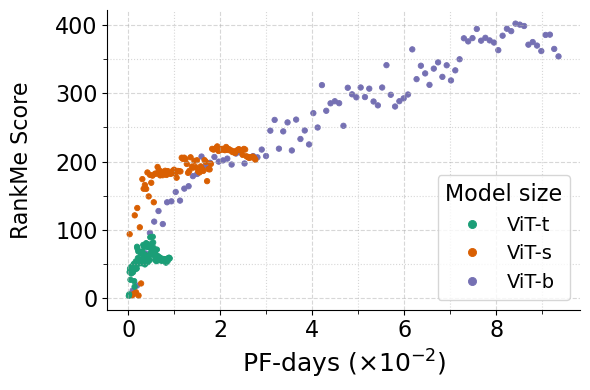

In [ ]:
f, ax = plt.subplots(figsize=(6, 4))
plt.ticklabel_format(style='sci', axis='x', scilimits=(6,-6))
ax.xaxis.get_offset_text().set_visible(False)
data = rm_df.copy() #.iloc[:10]
data['model'] = data['model'].map({'vit-t': 'ViT-t', 'vit-s': 'ViT-s', 'vit-b': 'ViT-b'})
sns.scatterplot(data=data,
                x='flops',
                y='rankme',
                ax=ax,
                hue='model',
                palette='Dark2',
                # map model name to specific color
                hue_order=['ViT-t', 'ViT-s', 'ViT-b'],
                style='model',
                markers='.',
                edgecolor=None,
                legend=True,
                s=60)
plt.xlabel(r'PF-days ($\times 10^{-2}$)', fontsize=18)
plt.ylabel('RankMe Score', fontsize=16, labelpad=16)
ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)

plt.xticks(fontsize=16)
ax.xaxis.set_minor_locator(AutoMinorLocator(2))  # 1 minor tick between major ticks
ax.tick_params(axis='x', which='minor', length=3)
plt.yticks([0, 100, 200, 300, 400] ,fontsize=16)
ax.yaxis.set_minor_locator(AutoMinorLocator(2))  # 1 minor tick between major ticks
# ax.tick_params(axis='y', which='major', length=5)
ax.tick_params(axis='y', which='minor', length=3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(visible=True, which='major', axis='both', linestyle='--', alpha=0.5)
plt.tight_layout()
legend = plt.legend(
    title='Model size',
    loc='lower right',
    fontsize=14,
    title_fontsize=16,
    markerscale=1.5
)
plt.show()

/tmp/ipykernel_1787595/3783539986.py:6: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(data=data,


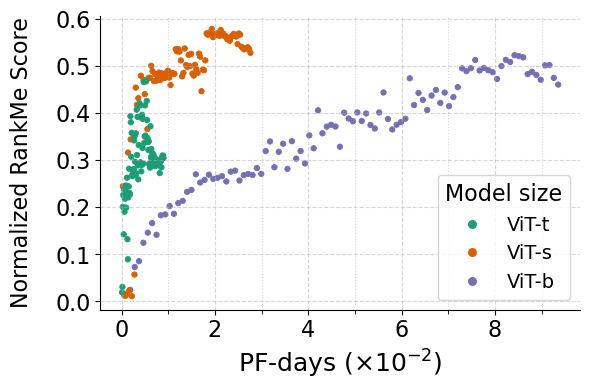

In [13]:
f, ax = plt.subplots(figsize=(6, 4))
plt.ticklabel_format(style='sci', axis='x', scilimits=(6,-6))
ax.xaxis.get_offset_text().set_visible(False)
data = rm_df.copy() #.iloc[:10]
data['model'] = data['model'].map({'vit-t': 'ViT-t', 'vit-s': 'ViT-s', 'vit-b': 'ViT-b'})
sns.scatterplot(data=data,
                x='flops',
                y='normalized_rankme',
                ax=ax,
                hue='model',
                palette='Dark2',
                hue_order=['ViT-t', 'ViT-s', 'ViT-b'],
                style='model',
                markers='.',
                edgecolor=None,
                legend=True,
                s=60)
# ax.set_title('RankMe vs. FLOPS')
# ax.set_ylabel('')
plt.xlabel(r'PF-days ($\times 10^{-2}$)', fontsize=18)
plt.ylabel('Normalized RankMe Score', fontsize=16, labelpad=16)
ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)
plt.xticks(fontsize=16)
ax.xaxis.set_minor_locator(AutoMinorLocator(2))  # 1 minor tick between major ticks
ax.tick_params(axis='x', which='minor', length=3)
plt.yticks(fontsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(visible=True, which='major', axis='both', linestyle='--', alpha=0.5)
plt.tight_layout()
legend = plt.legend(
    title='Model size',
    loc='lower right',
    fontsize=14,
    title_fontsize=16,
    markerscale=1.5
)
plt.show()

### Linear probing
Or online finetuner (OFT)

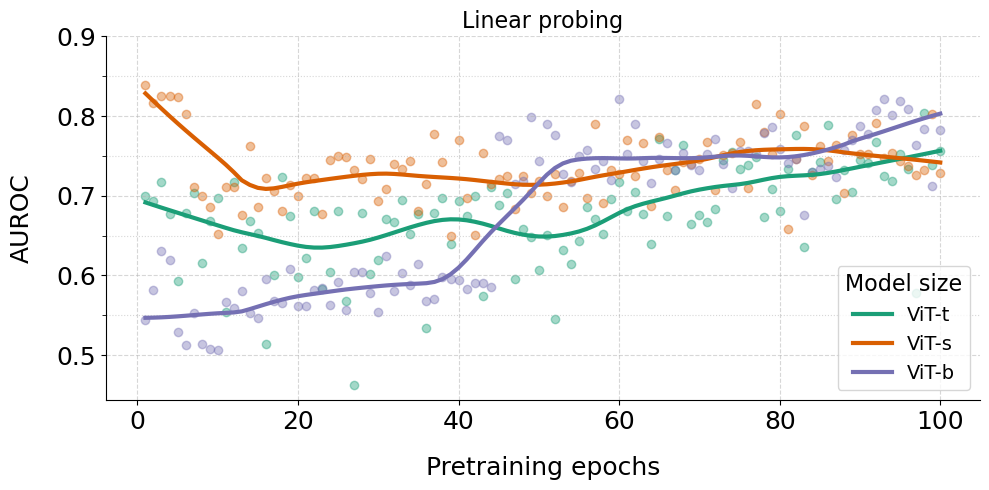

In [18]:
f, ax = plt.subplots(figsize=(10, 5))
# plt.ticklabel_format(style='sci', axis='x', scilimits=(6,-6))
alpha_scatter = 0.4
line_thickness = 3
data_tiny = rm_df[rm_df['model']=='vit-t']
tiny_color = 'dark2:0'
tiny_color = sns.color_palette('Dark2', 3)[0]
plt.scatter(data=data_tiny, x='epochs', y='lin-prob_auroc', alpha=alpha_scatter, color=tiny_color)
auroc_smooth_tiny = lowess(data_tiny['lin-prob_auroc'], data_tiny['epochs'], frac=0.25, it=3, return_sorted=False)
plt.plot(data_tiny['epochs'], auroc_smooth_tiny, label='ViT-t', linewidth=line_thickness, color=tiny_color)

data_small = rm_df[rm_df['model']=='vit-s']
small_color = sns.color_palette('Dark2', 3)[1]
plt.scatter(data=data_small, x='epochs', y='lin-prob_auroc', alpha=alpha_scatter, color=small_color)
auroc_smooth_small = lowess(data_small['lin-prob_auroc'], data_small['epochs'], frac=0.25, it=3, return_sorted=False)
plt.plot(data_small['epochs'], auroc_smooth_small, label='ViT-s', linewidth=line_thickness, color=small_color)

data_base = rm_df[rm_df['model']=='vit-b']
base_color = sns.color_palette('Dark2', 3)[2]
plt.scatter(data=data_base, x='epochs', y='lin-prob_auroc', alpha=alpha_scatter, color=base_color)
auroc_smooth_base = lowess(data_base['lin-prob_auroc'], data_base['epochs'], frac=0.25, it=3, return_sorted=False)
plt.plot(data_base['epochs'], auroc_smooth_base, label='ViT-b', linewidth=line_thickness, color=base_color)


plt.title('Linear probing', fontsize=16)
plt.xlabel('Pretraining epochs', fontsize=18, labelpad=16)
plt.ylabel('AUROC', fontsize=18, labelpad=16)
ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)

plt.xticks(fontsize=18)
ax.set_yticks([0.50, 0.60, 0.70, 0.80, 0.90])
ax.set_yticks([0.55, 0.65, 0.75, 0.85], minor=True)
ax.tick_params(axis='y', which='minor', length=3, labelleft=False)

plt.yticks(fontsize=18)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(visible=True, which='major', axis='both', linestyle='--', alpha=0.5)
plt.tight_layout()
line_handles = [line for line in ax.lines if not line.get_label().startswith('_')]
line_labels = [line.get_label() for line in line_handles]
ax.legend(line_handles, line_labels, loc='lower right', fontsize=14, title='Model size', title_fontsize=16)
plt.show()

## Correlations
Pretraining metrics vs feeding tube classification AUROC

In [2]:
def spearman_bootstrap_ci(x, y, n_bootstrap=10000, seed=42):
    """
    Bootstrap 95% CI for Spearman correlation.
    """

    x = np.asarray(x)
    y = np.asarray(y)

    rng = np.random.default_rng(seed)
    observed_rho, _ = spearmanr(x, y)
    bootstrap_rhos = []
    n = len(x)

    for _ in range(n_bootstrap):
        # Resample checkpoints
        idx = rng.integers(0, n, size=n)
        x_boot = x[idx]
        y_boot = y[idx]
        # Spearman can be undefined if all values are identical
        if len(np.unique(x_boot)) < 2 or len(np.unique(y_boot)) < 2:
            continue
        rho, _ = spearmanr(x_boot, y_boot)
        bootstrap_rhos.append(rho)

    bootstrap_rhos = np.asarray(bootstrap_rhos)
    lower = np.percentile(bootstrap_rhos, 2.5)
    upper = np.percentile(bootstrap_rhos, 97.5)

    return observed_rho, lower, upper

In [ ]:
downstream_results = pd.read_csv(data_path / 'pretrain-ablation_results.csv')
pretrained_epochs = sorted(downstream_results.pretrained_epoch.unique())
metrics_df = pd.read_csv(data_path / 'results_rm_loss_oft.csv')

METRICS = {
    "Normalized RankMe": "normalized_rankme",
    "Linear probing AUC": "lin-prob_auroc",
    "Validation loss": "loss",
}

MODELS = ["vit-t", "vit-s", "vit-b"]
METHODS = ["full_finetune", "lora"]

N_BOOTSTRAP = 10000
RANDOM_SEED = 42

all_rows = []

for mdl in MODELS:
    mdf = (
        metrics_df[(metrics_df["epochs"].isin(pretrained_epochs)) & (metrics_df["model"] == mdl)]
        .sort_values("epochs")
        .reset_index(drop=True)
    )

    for mth in METHODS:
        sub = downstream_results[
            (downstream_results.model == mdl)
            & (downstream_results.method == mth)
            & (downstream_results.pretrained_epoch.isin(pretrained_epochs))
        ]
        grouped = sub.groupby('pretrained_epoch')['auroc']
        y_mean = grouped.mean().reindex(mdf['epochs'].values).values
        y_std = grouped.std().reindex(mdf['epochs'].values).values

        for name, col in METRICS.items():
            x = mdf[col].values
            _, p_spearman = spearmanr(x, y_mean)
            rho, rho_low, rho_high = spearman_bootstrap_ci(
                x, y_mean, n_bootstrap=N_BOOTSTRAP, seed=RANDOM_SEED
            )
            all_rows.append({
                "model": mdl,
                "method": mth,
                "metric": name,
                "metric_col": col,
                "n_checkpoints": len(x),
                "spearman_rho": rho,
                "ci_low": rho_low,
                "ci_high": rho_high,
                "p_value": p_spearman,
            })

correlation_results = pd.DataFrame(all_rows)
correlation_results.to_csv(data_path / 'correlation_results_all.csv', index=False)

In [12]:
correlation_results

,model,method,metric,metric_col,n_checkpoints,spearman_rho,ci_low,ci_high,p_value
0,vit-t,full_finetune,Normalized RankMe,normalized_rankme,10,0.636364,-0.245283,0.987013,0.047912
1,vit-t,full_finetune,Linear probing AUC,lin-prob_auroc,10,0.539394,-0.222930,0.912500,0.107593
2,vit-t,full_finetune,Validation loss,loss,10,-0.818182,-0.987578,-0.304239,0.003815
3,vit-t,lora,Normalized RankMe,normalized_rankme,10,0.321212,-0.666830,0.887500,0.365468
4,vit-t,lora,Linear probing AUC,lin-prob_auroc,10,0.587879,-0.169811,0.962264,0.073878
5,vit-t,lora,Validation loss,loss,10,-0.975758,-1.000000,-0.810127,0.000001
6,vit-s,full_finetune,Normalized RankMe,normalized_rankme,10,0.927273,0.660377,1.000000,0.000112
7,vit-s,full_finetune,Linear probing AUC,lin-prob_auroc,10,0.818182,0.207547,1.000000,0.003815
8,vit-s,full_finetune,Validation loss,loss,10,-0.781818,-0.987654,-0.119497,0.007547
9,vit-s,lora,Normalized RankMe,normalized_rankme,10,0.890909,0.487500,1.000000,0.000542


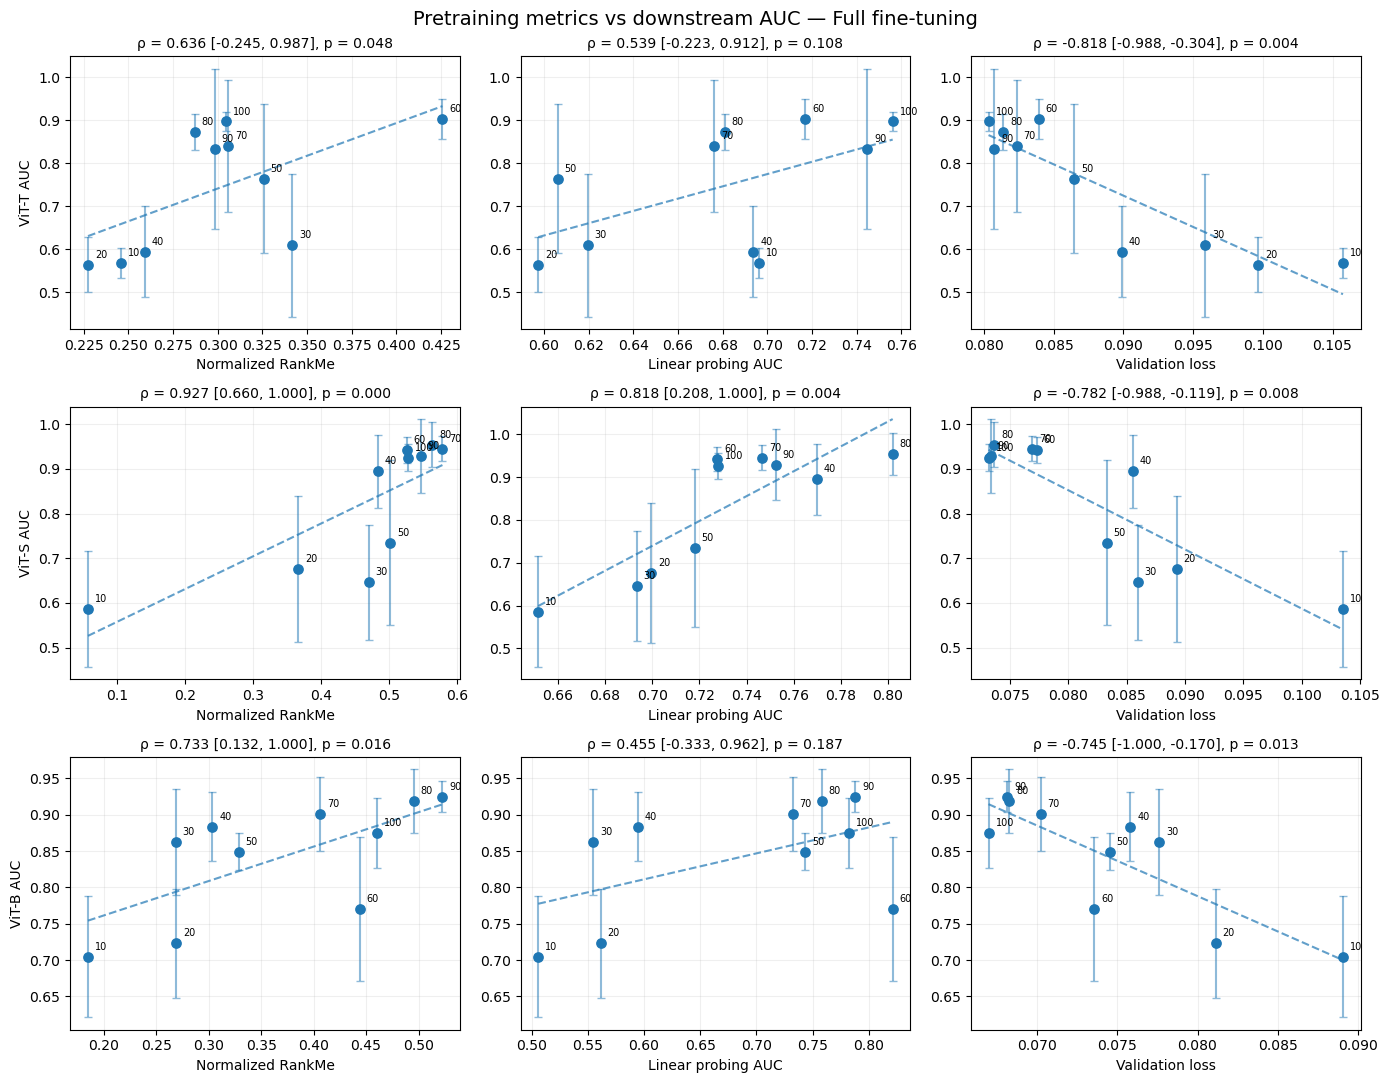

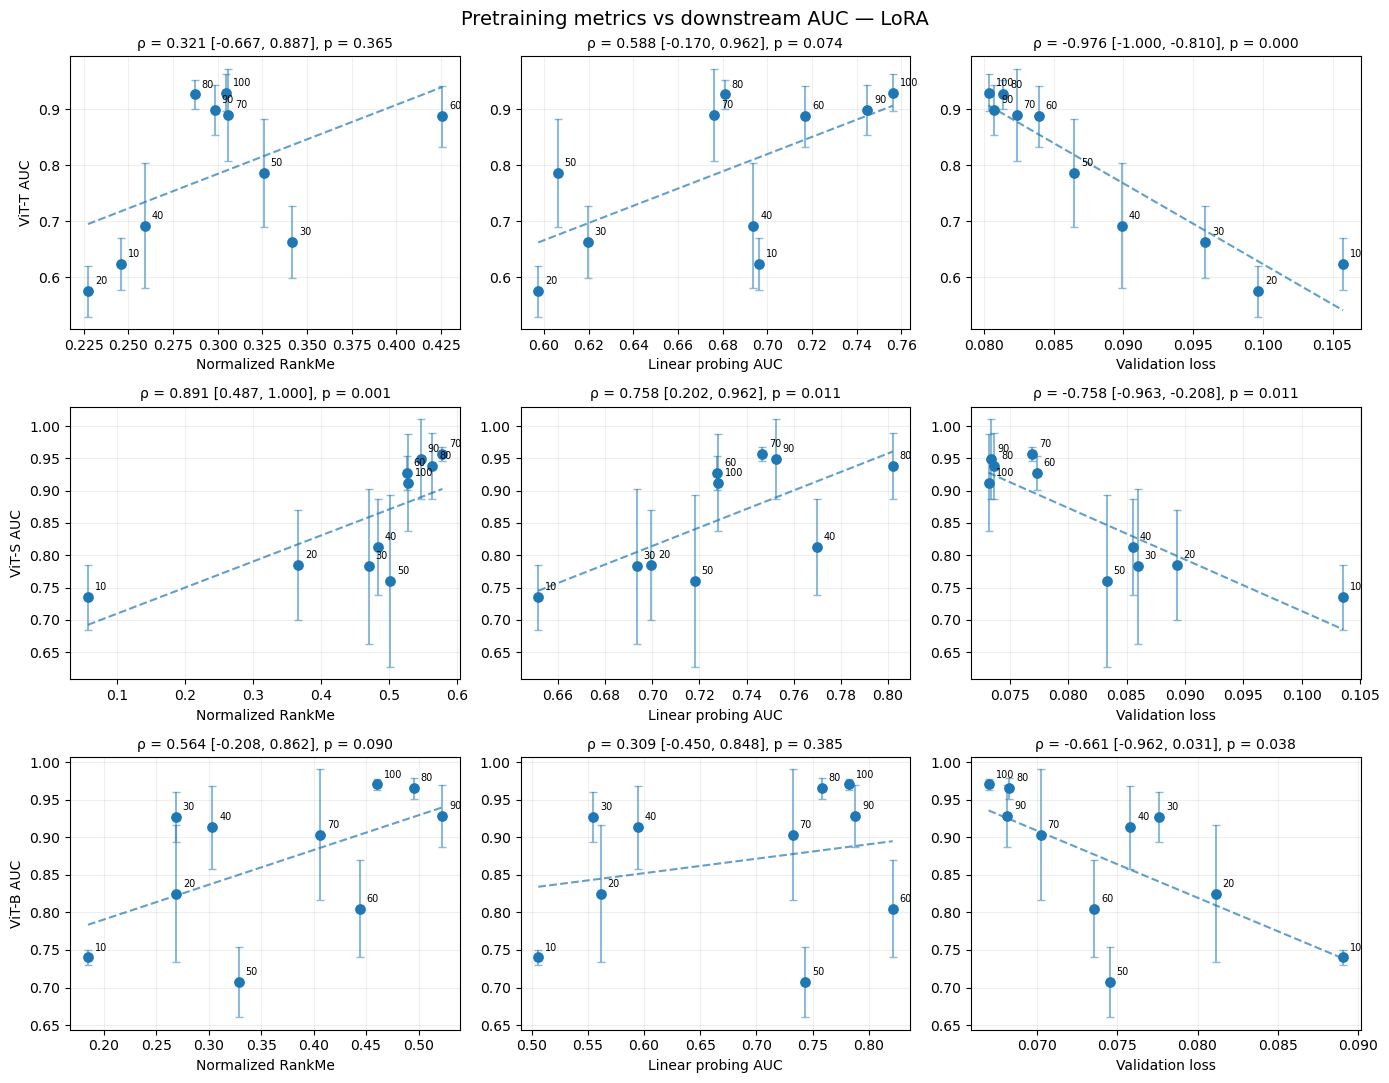

In [ ]:
corr_df = pd.read_csv(data_path / 'correlation_results_all.csv')
metrics_all = pd.read_csv(data_path / 'results_rm_loss_oft.csv')
downstream_all = pd.read_csv(data_path / 'pretrain-ablation_results.csv')

epochs = sorted(downstream_all.pretrained_epoch.unique())

MODELS = ["vit-t", "vit-s", "vit-b"]
METHODS = ["full_finetune", "lora"]
MODEL_LABEL = {"vit-t": "ViT-T", "vit-s": "ViT-S", "vit-b": "ViT-B"}
METHOD_LABEL = {"full_finetune": "Full fine-tuning", "lora": "LoRA"}
METRIC_ORDER = ["Normalized RankMe", "Linear probing AUC", "Validation loss"]
METRIC_COL = dict(zip(corr_df.metric, corr_df.metric_col))

for mth in METHODS:
    fig, axes = plt.subplots(
        len(MODELS),
        len(METRIC_ORDER),
        figsize=(14, 11),
    )

    for i, mdl in enumerate(MODELS):
        mdf = (
            metrics_all[(metrics_all.epochs.isin(epochs)) & (metrics_all.model == mdl)]
            .sort_values("epochs")
            .reset_index(drop=True)
        )
        grouped = downstream_all[
            (downstream_all.model == mdl)
            & (downstream_all.method == mth)
            & (downstream_all.pretrained_epoch.isin(epochs))
        ].groupby('pretrained_epoch')['auroc']

        y_mean = grouped.mean().reindex(mdf['epochs'].values).values
        y_std = grouped.std().reindex(mdf['epochs'].values).values

        for j, name in enumerate(METRIC_ORDER):
            ax = axes[i, j]
            x = mdf[METRIC_COL[name]].values

            r = corr_df[
                (corr_df.model == mdl) & (corr_df.method == mth) & (corr_df.metric == name)
            ].iloc[0]

            ax.scatter(x, y_mean, s=45, zorder=3)
            ax.errorbar(x, y_mean, yerr=y_std, fmt="none", capsize=3, alpha=0.5, zorder=2)

            for xi, yi, ep in zip(x, y_mean, mdf['epochs'].values):
                ax.annotate(
                    str(ep), (xi, yi), xytext=(5, 5), textcoords="offset points", fontsize=7
                )

            slope, intercept = np.polyfit(x, y_mean, 1)
            x_line = np.linspace(x.min(), x.max(), 100)
            ax.plot(x_line, slope * x_line + intercept, linestyle="--", alpha=0.7)

            ax.set_xlabel(name)
            ax.set_ylabel(f"{MODEL_LABEL[mdl]} AUC" if j == 0 else "")
            ax.set_title(
                f"ρ = {r.spearman_rho:.3f} "
                f"[{r.ci_low:.3f}, {r.ci_high:.3f}], "
                f"p = {r.p_value:.3f}",
                fontsize=10,
            )
            ax.grid(alpha=0.2)

    fig.suptitle(f"Pretraining metrics vs downstream AUC — {METHOD_LABEL[mth]}", fontsize=14)
    fig.tight_layout()
    plt.show()
